In [ ]:
!pip install 'qiskit>=2.1.0' 'qiskit-ibm-runtime>=0.40.1' 'qiskit-aer>=0.17.0' 'numpy' 'pylatexenc'

# **АЛГОРИТМ ДОЙЧА И ДОЙЧА-ЙОЖИ**

## Введение

В начале 1980-х годов квантовые физики и специалисты по информатике имели смутное представление о том, что квантовую механику можно использовать для выполнения вычислений, которые были бы намного более мощными, чем классические компьютеры. Они рассуждали так: классическому компьютеру сложно моделировать квантовые системы, но квантовый компьютер должен быть способен делать это более эффективно. И если квантовый компьютер может моделировать квантовые системы более эффективно, возможно, существуют и другие задачи, которые он мог бы выполнять более эффективно, чем классический компьютер.

Логика была здравой, но детали еще предстояло проработать. Это началось в 1985 году, когда Дэвид Дойч описал первый "универсальный квантовый компьютер". В этой же статье он привел первый пример задачи, которую квантовый компьютер мог бы решить более эффективно, чем классический компьютер. Этот первый игрушечный пример теперь известен как "алгоритм Дойча". Усовершенствование алгоритма Дойча было незначительным, но несколько лет спустя Дойч работал с Ричардом Йожи над дальнейшим увеличением разрыва между классическими и квантовыми компьютерами.

Эти алгоритмы — Дойча и расширение Дойча-Йожи — не особенно полезны, но они по-прежнему очень важны по нескольким причинам:

1. Исторически сложилось так, что они были одними из первых квантовых алгоритмов, которые, как было продемонстрировано, превзошли свои классические аналоги. Понимание их может помочь нам понять, как со временем менялось отношение сообщества к квантовым вычислениям.
2. Они могут помочь нам понять некоторые аспекты ответа на удивительно тонкий вопрос: что придает квантовым вычислениям такую мощь? Иногда квантовые компьютеры сравнивают с гигантскими параллельными процессорами экспоненциального масштабирования. Но это не совсем верно. Хотя частично ответ на этот вопрос заключается в так называемом "квантовом параллелизме", извлечение как можно большего количества информации за один запуск – это тонкое искусство. Алгоритмы Дойча и Дойча-Йожи показывают, как это можно сделать.



## Квантовый параллелизм и его пределы
Часть возможностей квантовых вычислений основана на "квантовом параллелизме", который, по сути, заключается в способности выполнять операции с несколькими входами одновременно, поскольку входные состояния кубита могут находиться в суперпозиции нескольких классически разрешенных состояний. ОДНАКО, хотя квантовая схема может быть способна оценивать несколько входных состояний одновременно, извлечение всей этой информации за один раз невозможно.

Чтобы понять, что я имею в виду, давайте предположим, что у нас есть бит $x$ и некоторая функция, применяемая к этому биту $f(x)$. Существуют четыре возможные двоичные функции, преобразующие один бит в другой один бит:

|$x$|$f_1(x)$|$f_2(x)$|$f_3(x)$|$f_4(x)$|
|--|--|--|--|--|
|0|⠀⠀0⠀⠀|⠀⠀0⠀⠀|⠀⠀1⠀⠀|⠀⠀1⠀⠀|
|1|⠀⠀0⠀⠀|⠀⠀1⠀⠀|⠀⠀0⠀⠀|⠀⠀1⠀⠀|

Мы хотели бы выяснить, какой из этих функций (1-4) является наша $f(x)$. В классическом случае нам нужно было бы запустить функцию дважды — один раз для
$x=0$, один раз для $x=1$. Но давайте посмотрим, сможем ли мы добиться большего успеха с помощью квантовой схемы. Мы можем узнать о функции с помощью следующего вентиля:


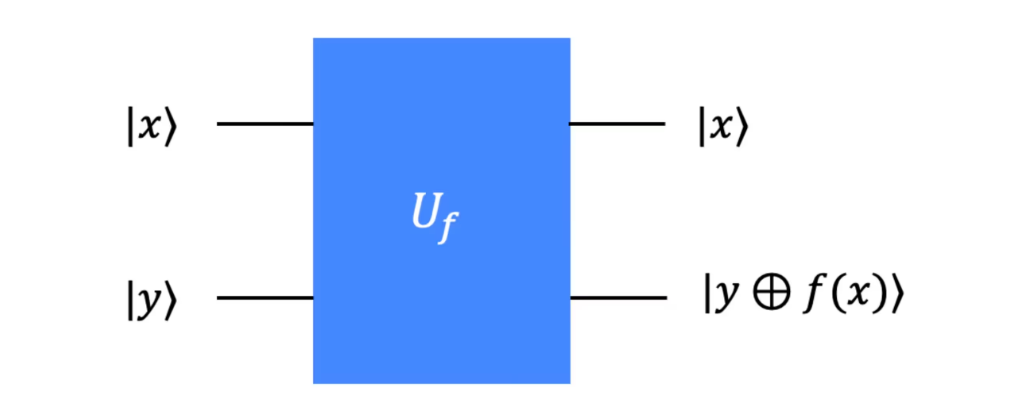

In [ ]:
from IPython.display import Image, display
Image('quantum_parallelism.png', width="700")

Здесь вентиль $U_f$ вычисляет $f(x)$, где $x$ - состояние кубита 0, и применяет его к кубиту 1. Таким образом, результирующее состояние $∣x\rangle∣y⊕f(x)\rangle$, просто становится $∣x\rangle∣f(x)\rangle$ когда $∣y\rangle=∣0\rangle$. Здесь содержится вся информация, необходимая для определения функции $f(x)$: кубит 0 сообщает нам, что такое $x$, а кубит 1 - чему равняется $f(x)$. Итак, если мы инициализируем $∣x\rangle=\frac{1}{\sqrt{2}}(∣0\rangle+∣1\rangle)$, тогда конечным состоянием обоих кубитов будет: $∣y\rangle∣x\rangle = \frac{1}{\sqrt{2}}(∣f(0)\rangle∣0\rangle+∣f(1)\rangle∣1\rangle)$. Но как нам получить доступ к этой информации?

## Реализация на Qiskit
Используя Qiskit, мы случайным образом выберем одну из четырех возможных функций, описанных выше, и запустим схему. Затем ваша задача - использовать измерения квантовой схемы, чтобы изучить функцию за как можно меньшее количество запусков.

В этом первом эксперименте и на протяжении всего модуля мы будем использовать фреймворк для квантовых вычислений, известный как "Qiskit patterns", который разбивает рабочие процессы на следующие этапы:
1. Сопоставьте классические входные данные с квантовой задачей
2. Составьте квантовую схему
3. Выполнение с использованием примитивов среды выполнения Qiskit
4. Постобработка и классический анализ

Давайте начнем с загрузки некоторых необходимых пакетов, включая примитивы среды выполнения Qiskit.

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.primitives import BackendSamplerV2
import numpy as np
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

backend_sim = AerSimulator()
sampler = BackendSamplerV2(backend=backend_sim)

print("Локальный симулятор Aer настроен успешно!")

Локальный симулятор Aer настроен успешно!


Теперь, когда мы загрузили необходимые пакеты, мы можем приступить к работе с шаблонами Qiskit. На следующем шаге сопоставления мы сначала создаем функцию, которая выбирает одну из четырех возможных функций, преобразуя один бит в другой.

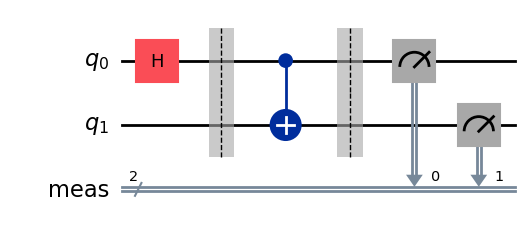

In [ ]:
# Шаг 1: Сопоставление
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

def twobit_function(case: int):
    """Сгенерируйте допустимую двухбитовую функцию в виде квантовой схемы."""
    if case not in [1, 2, 3, 4]:
        raise ValueError("`case` должен быть 1, 2, 3, or 4.")

    f = QuantumCircuit(2)
    if case in [2, 3]:
        f.cx(0, 1)
    if case in [3, 4]:
        f.x(1)
    return f

# сначала преобразуйте схему оракула (приведенную выше) в один элемент. в противном случае схема будет слишком большой для отображения
# blackbox = twobit_function(2).to_gate() # вы можете изменить номер внутри "twobit_function()", чтобы выбрать одну из четырех допустимых функций
# blackbox.label = "$U_f$"

qc.h(0)
qc.barrier()
qc.compose(twobit_function(2), inplace=True)
qc.measure_all()


qc.draw("mpl")

В приведенной выше схеме вентиль Адамара $H$ принимает кубит 0, который изначально находится в состоянии $∣0\rangle$, в состояние суперпозиции
$\frac{1}{\sqrt{2}}(∣0\rangle + ∣1\rangle)$. Затем, $U_f$ вычисляет функцию $f(x)$ и применяет ее к кубиту 1.

In [ ]:
# Шаг 2: Создание схемы квантового параллелизма
qc = QuantumCircuit(2)
qc.h(0)
qc.barrier()
qc.compose(twobit_function(2), inplace=True)  # Использование функции 2 в качестве примера
qc.measure_all()

print("Схема квантового параллелизма:")
print(qc.draw())

Схема квантового параллелизма:
        ┌───┐ ░       ░ ┌─┐   
   q_0: ┤ H ├─░───■───░─┤M├───
        └───┘ ░ ┌─┴─┐ ░ └╥┘┌─┐
   q_1: ──────░─┤ X ├─░──╫─┤M├
              ░ └───┘ ░  ║ └╥┘
meas: 2/═════════════════╩══╩═
                         0  1 


In [ ]:
# Шаг 3: Запуск на симуляторе Aer
job = sampler.run([qc], shots=1)  # Можно увеличить параметр shots для лучшей статистики
res = job.result()
counts = res[0].data.meas.get_counts()

print("Результат выполнения на симуляторе:", counts)

Результат выполнения на симуляторе: {'11': 1}


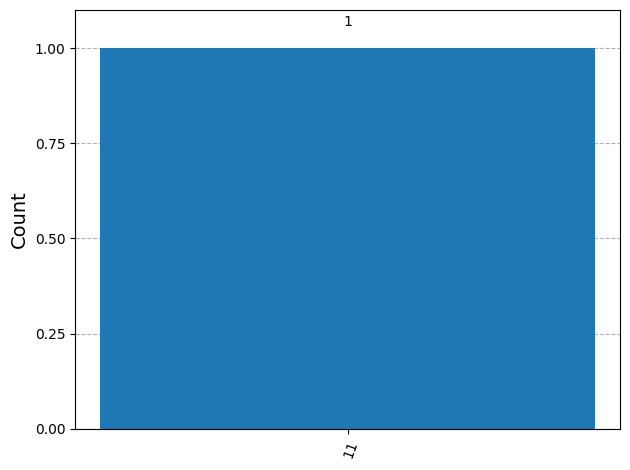

In [ ]:
# Шаг 4: Визуализация и анализ результатов
plot_histogram(counts)

Выше приведена гистограмма наших результатов. В зависимости от количества снимков (shots), которые вы выбрали для запуска схемы на шаге 3 выше, вы можете увидеть один или два столбики, представляющие измеренные состояния двух кубитов на каждом снимке.
Итак, поскольку кубит 0 находился в состоянии суперпозиции, схема вычисляла функцию как для $x=0$, так и для $x=1$ одновременно — чего не могут сделать классические компьютеры. Но загвоздка возникает, когда мы хотим узнать о функции $f(x)$ — когда мы измеряем кубиты, мы сворачиваем их состояние. Если вы выберете "shots = 1", чтобы запустить программу только один раз, вы увидите только один столбик на гистограмме выше, и ваша информация о функции будет неполной.

## Проверьте свое понимание
Прочтите вопросы ниже, подумайте над своим ответом, затем сверьтесь с ответом, нажав на треугольник.


<details>
  <summary>
    Сколько раз мы должны выполнить описанный выше алгоритм, чтобы узнать функцию $f(x)$? Чем это лучше классического случая? Что бы вы предпочли - классический или квантовый компьютер для решения этой проблемы?
  </summary>

  **Ответ:** Поскольку измерение разрушит суперпозицию и вернет только одно значение, нам нужно запустить схему по крайней мере дважды, чтобы вернуть оба выходных сигнала функции $f(0)$ и $f(1)$. В лучшем случае это работает так же хорошо, как и в классическом случае, когда мы вычисляем как $f(0)$, так и $f(1)$ в первых двух запросах. Но есть вероятность, что нам потребуется выполнить код более двух раз, поскольку итоговое измерение является вероятностным и может возвращать одно и то же значение $f(x)$ в первые два раза. В этом случае предпочтительно использовать классический компьютер.
</details>

Таким образом, хотя квантовый параллелизм может быть эффективным, если его правильно использовать, неверно говорить, что квантовый компьютер работает так же, как массивный классический параллельный процессор. Процесс измерения разрушает квантовые состояния, поэтому мы можем получить доступ только к одному результату вычислений.

## Алгоритм Дойча

Хотя квантовый параллелизм сам по себе не дает нам преимущества перед классическими компьютерами, мы можем объединить его с другим квантовым явлением, интерференцией, для достижения ускорения. Алгоритм, известный сейчас как "алгоритм Дойча", является первым примером алгоритма, который позволяет достичь этого.

### Задача

Учитывая входной бит, $x = \{0,1\}$, и входную функцию $f(x) = \{0,1\}$, определить, является ли функция *сбалансированной* или *постоянной*. То есть, если она сбалансирована, то выходные данные функции в половине случаев равны 0, а в другой половине - 1. Если она постоянна, то на выходе функции всегда либо 0, либо 1. Вспомните таблицу с четырьмя возможными функциями, преобразующими один бит в другой, используя только один бит:

|$x$|$f_1(x)$|$f_2(x)$|$f_3(x)$|$f_4(x)$|
|--|--|--|--|--|
|0|⠀⠀0⠀⠀|⠀⠀0⠀⠀|⠀⠀1⠀⠀|⠀⠀1⠀⠀|
|1|⠀⠀0⠀⠀|⠀⠀1⠀⠀|⠀⠀0⠀⠀|⠀⠀1⠀⠀|

Первая и последняя функции, $f_1(x)$ и $f_4(x)$, являются постоянными, в то время как две функции посредине, $f_2(x)$ и $f_3(x)$, сбалансированы.



### Алгоритм

Дойч подошел к этой проблеме с помощью "модели запросов". В модели запроса входная функция ($f_i(x)$ выше) содержится в "черном ящике" — у нас нет прямого доступа к ее содержимому, но мы можем делать запросы к черному ящику, и он выдаст нам выходные данные функции. Иногда говорится, что эту информацию предоставляет "оракул".

Чтобы определить, является ли квантовый алгоритм более эффективным, чем классический алгоритм в модели запросов, мы можем просто сравнить количество запросов, которые нам нужно выполнить к черному ящику в каждом конкретном случае. В классическом случае, чтобы узнать, является ли функция, содержащаяся в черном ящике, сбалансированной или постоянной, нам нужно было бы произвести запросы два раза, чтобы получить как $f(0)$, так и $f(1)$.

Однако в квантовом алгоритме Дойча найден способ получать информацию с помощью всего одного запроса. Была внесена одна поправку в схему "квантового параллелизма", описанную выше, чтобы создать состояние суперпозиции на *обоих* кубитах, а не только на кубите 0. Затем два выходных сигнала функции, $f(0)$ и $f(1)$, взаимодействовали, возвращая 0, если они были либо равны 0, либо равны 1 (функция была постоянной), и возвращали 1, если они были разными (функция была сбалансирована). Таким образом, Дойч смог провести различие между постоянной и сбалансированной функцией с помощью одного запроса.

Вот принципиальная схема алгоритма Дойча:





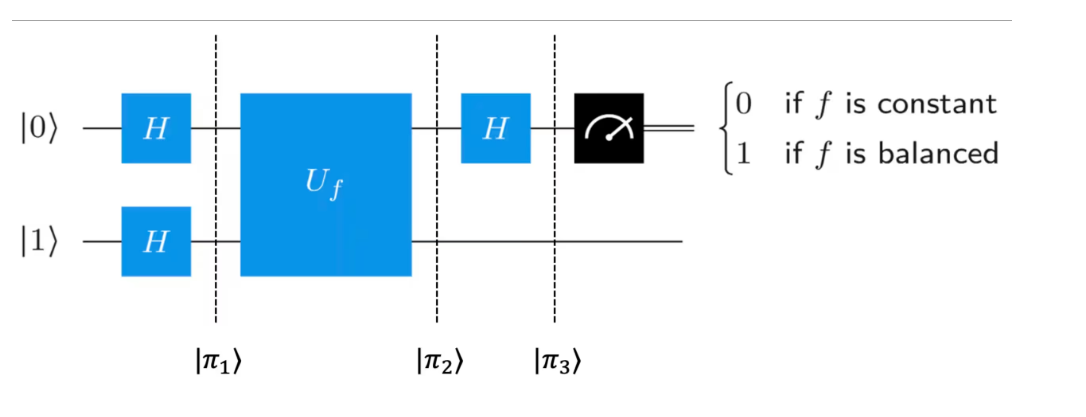

In [ ]:
from IPython.display import Image, display
Image('deutsch_algorithm.png', width="700")

Чтобы понять, как работает этот алгоритм, давайте посмотрим на квантовые состояния кубитов в трех точках, отмеченных на диаграмме выше. Попробуйте определить эти состояния самостоятельно, прежде чем переходить к просмотру ответов:

#### Проверьте свое понимание

Прочтите приведенные ниже вопросы, подумайте над своими ответами, затем нажмите на треугольники, чтобы увидеть ответы.

<details>
  <summary>
    Чему равно состояние $|\pi_1\rangle$?
  </summary>

  **Ответ:**

  Применение вентиля Адамара преобразует состояние $|0\rangle$ в $\frac{1}{\sqrt{2}}(|0\rangle+|1\rangle)$ и состояние $|1\rangle$ в  $\frac{1}{\sqrt{2}}(|0\rangle-|1\rangle)$. Таким образом, полное состояние становится: $|\pi_1\rangle = [\frac{|0\rangle-|1\rangle}{\sqrt{2}}][\frac{|0\rangle+|1\rangle}{\sqrt{2}}]$
</details>

<details>
  <summary>
    Чему равно состояние $|\pi_2\rangle$?
  </summary>

  **Ответ:**

  Перед применением операции $U_f$, давайте вспомним, что она делает. Она изменит состояние кубита 1 в зависимости от состояния кубита 0. Таким образом, имеет смысл исключить состояние кубита 0: $|\pi_1\rangle = \frac{1}{2} (|0\rangle-|1\rangle)|0\rangle+\frac{1}{2}(|0\rangle-|1\rangle)|1\rangle$. Затем, если $f(0)=f(1)$, данные два термина преобразуются одинаково, и относительный знак между ними остается положительным, но если $f(0)\neq f(1)$, тогда это означает, что второй термин получит знак минус относительно первого термина, изменяя состояние кубита 0 с $\frac{1}{\sqrt{2}}(|0\rangle+|1\rangle)$ на $\frac{1}{\sqrt{2}}(|0\rangle-|1\rangle)$. Так что:

  $$
  |\pi_2\rangle = \begin{cases}
  \pm[\frac{|0\rangle-|1\rangle}{\sqrt{2}}][\frac{|0\rangle+|1\rangle}{\sqrt{2}}] & \text{если} & f(0) = f(1) \\
  \pm[\frac{|0\rangle-|1\rangle}{\sqrt{2}}][\frac{|0\rangle-|1\rangle}{\sqrt{2}}] &\text{если} & f(0) \neq f(1) \\
  \end{cases}
  $$
</details>

<details>
  <summary>
    Чему равно состояние $|\pi_3\rangle$?
  </summary>

  **Ответ:**

  Теперь, состояние кубита 0 является либо $\frac{1}{\sqrt{2}}(|0\rangle+|1\rangle)$, либо $\frac{1}{\sqrt{2}}(|0\rangle-|1\rangle)$, зависимо от функции. Применение вентиля Адамара приведет к получению либо $|0\rangle$, либо $|1\rangle$, соответственно.

  $$
  |\pi_3\rangle = \begin{cases}
  \pm[\frac{|0\rangle-|1\rangle}{\sqrt{2}}]|0\rangle & \text{если} & f(0) = f(1) \\
  \pm[\frac{|0\rangle-|1\rangle}{\sqrt{2}}]|1\rangle &\text{если} & f(0) \neq f(1) \\
  \end{cases}
  $$
</details>

Просматривая ваши ответы на вышеперечисленные вопросы, обратите внимание, что происходит нечто немного неожиданное. Хотя $U_f$ явно не влияет на состояние кубита 0, поскольку он изменяет кубит 1 в зависимости от состояния кубита 0, может случиться так, что это вызовет фазовый сдвиг в кубите 0. Это явление известно как "фазовый откат".

Теперь, когда мы понимаем, как работает этот алгоритм, давайте реализуем его с помощью Qiskit.

In [ ]:
# Шаг 2: Создайте схему алгоритма Дойча
qc_deutsch = QuantumCircuit(2, 1)
qc_deutsch.x(1)
qc_deutsch.h(range(2))
qc_deutsch.barrier()
qc_deutsch.compose(twobit_function(2), inplace=True)  # Используем функцию 2 как пример
qc_deutsch.barrier()
qc_deutsch.h(0)
qc_deutsch.measure(0, 0)

print("Схема алгоритма Дойча:")
print(qc_deutsch.draw())

Схема алгоритма Дойча:
     ┌───┐      ░       ░ ┌───┐┌─┐
q_0: ┤ H ├──────░───■───░─┤ H ├┤M├
     ├───┤┌───┐ ░ ┌─┴─┐ ░ └───┘└╥┘
q_1: ┤ X ├┤ H ├─░─┤ X ├─░───────╫─
     └───┘└───┘ ░ └───┘ ░       ║ 
c: 1/═══════════════════════════╩═
                                0 


In [ ]:
# Шаг 3: Запуск на локальном симуляторе
job = sampler.run([qc_deutsch], shots=1)
res = job.result()
counts = res[0].data.c.get_counts()

print(f"\nРезультат измерения: {counts}")


Результат измерения: {'1': 1}


In [ ]:
# Шаг 4: Определите является ли функция постоянной или сбалансированной
if "1" in counts:
    print("Результант: функция сбалансирована")
else:
    print("Результат: функция постоянна")

Результант: функция сбалансирована


## Алгоритм Дойча-Йожи
Алгоритм Дойча стал важным первым шагом в демонстрации того, как квантовый компьютер может быть более эффективным, чем классический, но это было лишь скромное улучшение: он требовал всего одного запроса по сравнению с двумя в классическом случае. В 1992 году Дойч и его коллега Ричард Йожи расширили первоначальный двухкубитный алгоритм на большее количество кубитов. Задача осталась прежней: определить, является ли функция *сбалансированной* или *постоянной*. Но на этот раз функция переходит от $n$ битов к одному биту. Либо функция возвращает 0 и 1 равное количество раз (это *сбалансированная функция*), либо функция всегда возвращает 1 или всегда 0 (это *постоянная функция*).

Вот принципиальная схема алгоритма Дойча-Йожи:






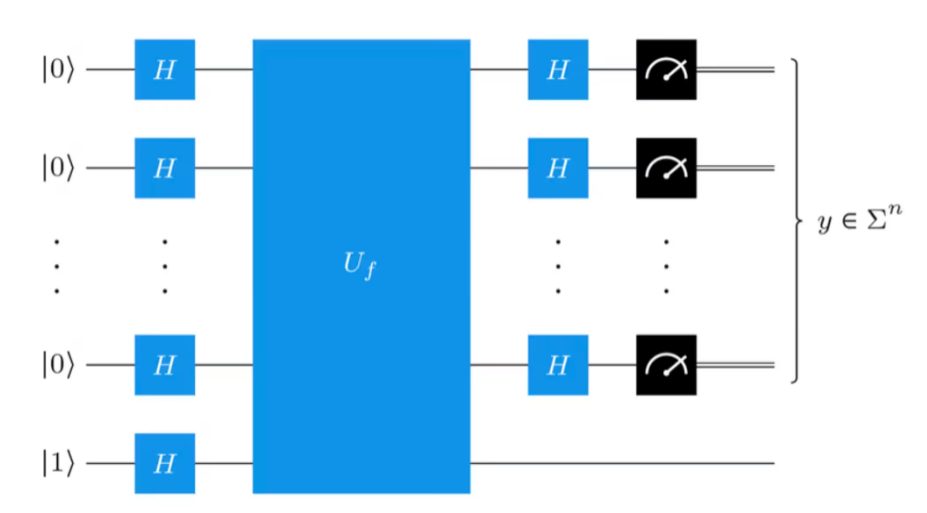

In [ ]:
from IPython.display import Image, display
Image('deutsch_josa_algorithm.png', width="700")

Данный алгоритм работает так же, как и алгоритм Дойча: фазовый откат позволяет считывать состояние кубита 0, чтобы определить, является ли функция постоянной или сбалансированной. Это немного сложнее увидеть, чем в случае алгоритма Дойча с двумя кубитами, поскольку состояния будут включать суммы по $n$ кубитам. Алгоритм вернет битовую строку, содержащую все 0, если функция постоянна, и битовую строку, содержащую хотя бы одну единицу, если функция сбалансирована.

Чтобы увидеть, как работает алгоритм в Qiskit, сначала нам нужно сгенерировать наш оракул: случайную функцию, которая гарантированно будет либо постоянной, либо сбалансированной. Приведенный ниже код будет генерировать сбалансированную функцию в 50% случаев и постоянную функцию в 50% случаев.

In [ ]:
# Шаг 1: Создание случайной функции Дойча-Йожи
def dj_function(num_qubits):
    qc_dj = QuantumCircuit(num_qubits + 1)

    # 50% шанса вернуть постоянную функцию
    if np.random.randint(0, 2):
        # Инверсия выходных кубитов с 50% вероятностью
        if np.random.randint(0, 2):
            qc_dj.x(num_qubits)
        return qc_dj

    # Создание сбалансированной функции
    on_states = np.random.choice(
        range(2**num_qubits),
        2**num_qubits // 2,
        replace=False,
    )

    def add_cx(qc_dj, bit_string):
        for qubit, bit in enumerate(reversed(bit_string)):
            if bit == "1":
                qc_dj.x(qubit)
        return qc_dj

    for state in on_states:
        qc_dj = add_cx(qc_dj, f"{state:0b}")
        qc_dj.mcx(list(range(num_qubits)), num_qubits)
        qc_dj = add_cx(qc_dj, f"{state:0b}")

    return qc_dj

Это функция оракула, которая является либо сбалансированной, либо постоянной. Можете ли вы, посмотрев на нее, определить, зависит ли вывод на последнем кубите от значений, введенных для первых $n$ кубитов? Если выходной сигнал для последнего кубита зависит от первых $n$ кубитов, можете ли вы определить, сбалансирован ли этот зависимый выходной сигнал или нет?

Мы можем определить, является ли функция сбалансированной или постоянной, посмотрев на приведенную выше схему, но помните, что для решения этой задачи мы рассматриваем эту функцию как "черный ящик". Мы не можем заглянуть в коробку, чтобы посмотреть на принципиальную схему. Вместо этого нам нужно производить запросы к ней.

Чтобы произвести запрос, мы используем алгоритм Дойча-Йожи и определяем, является ли функция постоянной или сбалансированной:

In [ ]:
# Шаг 2: Создание схемы алгоритма Дойча-Йожи
n = 3  # число входных кубитов

oracle = dj_function(n)

qc_dj = QuantumCircuit(n + 1, n)
qc_dj.x(n)
qc_dj.h(range(n + 1))
qc_dj.barrier()
qc_dj.compose(oracle, inplace=True)
qc_dj.barrier()
qc_dj.h(range(n))
qc_dj.measure(range(n), range(n))

print(f"Схема Дойча-Йожи ({n} входных кубитов):")
print(qc_dj.draw())

Схема Дойча-Йожи (3 входных кубитов):
     ┌───┐      ░           ┌───┐     ┌───┐                ░ ┌───┐┌─┐      
q_0: ┤ H ├──────░────────■──┤ X ├──■──┤ X ├──■─────────■───░─┤ H ├┤M├──────
     ├───┤      ░ ┌───┐  │  ├───┤  │  ├───┤  │  ┌───┐  │   ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├──────░─┤ X ├──■──┤ X ├──■──┤ X ├──■──┤ X ├──■───░─┤ H ├─╫─┤M├───
     ├───┤      ░ ├───┤  │  ├───┤  │  └───┘  │  └───┘  │   ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├──────░─┤ X ├──■──┤ X ├──■─────────■─────────■───░─┤ H ├─╫──╫─┤M├
     ├───┤┌───┐ ░ └───┘┌─┴─┐└───┘┌─┴─┐     ┌─┴─┐     ┌─┴─┐ ░ └───┘ ║  ║ └╥┘
q_3: ┤ X ├┤ H ├─░──────┤ X ├─────┤ X ├─────┤ X ├─────┤ X ├─░───────╫──╫──╫─
     └───┘└───┘ ░      └───┘     └───┘     └───┘     └───┘ ░       ║  ║  ║ 
c: 3/══════════════════════════════════════════════════════════════╩══╩══╩═
                                                                   0  1  2 


In [ ]:
# Шаг 3: Запуск на локальном симуляторе
job = sampler.run([qc_dj], shots=1)
res = job.result()
counts = res[0].data.c.get_counts()

print(f"\nРезультаты измерения: {counts}")


Результаты измерения: {'001': 1}


In [ ]:
# Шаг 4: Определите является ли функция постоянной или сбалансированной
if "0" * n in counts:
    print("Результат: функция постоянна")
else:
    print("Результат: функция сбалансирована")

Результат: функция сбалансирована


Выше, первая строка выходных данных представляет собой битовую строку результатов измерения. Во второй строке указывается, означает ли битовая строка, что функция была сбалансированной или постоянной. Если битовая строка содержит все нули, то функция была постоянной; если нет, то она была сбалансирована. Таким образом, с помощью всего лишь одного запуска приведенной выше квантовой схемы мы можем определить, является ли функция постоянной или сбалансированной.

####Проверьте свое понимание
Прочитайте вопросы ниже, подумайте над своими ответами, затем нажмите на треугольники, чтобы увидеть решения.

<details>
  <summary>
    Сколько запросов потребовалось бы классическому компьютеру, чтобы со 100% уверенностью определить, является ли функция постоянной или сбалансированной? Помните, что в классическом случае один запрос позволяет применить функцию только к одной битовой строке.
  </summary>

  **Ответ:**

  Существует $ 2 ^ n $ возможных битовых строк для проверки, и в худшем случае вам нужно будет протестировать $ 2 ^ n/2 + 1 $ из них. Например, если функция была постоянной, и вы продолжали измерять "1" в качестве выходных данных функции, то вы не могли быть уверены, что она действительно постоянна, пока не проверили более половины результатов. До этого вам, возможно, просто очень не везло, если вы продолжали измерять значение "1" в сбалансированной функции. Это все равно, что подбрасывать монетку снова и снова, и каждый раз она выпадает орлом. Это маловероятно, но не невозможно.
   For example, if the function were constant, and you kept measuring "1" as the output of the function, then you couldn't be certain that it was truly constant until you checked over half of the results. Before then, you might have just been very unlucky to keep measuring "1" on a balanced function. It's like flipping a coin over and over and it landing heads every time. It's unlikely, but not impossible.
  There are $2^n$ possible bitstrings to check, and in the worst case, you would need to test $2^n/2+1$ of these. For example, if the function were constant, and you kept measuring "1" as the output of the function, then you couldn't be certain that it was truly constant until you checked over half of the results. Before then, you might have just been very unlucky to keep measuring "1" on a balanced function. It's like flipping a coin over and over and it landing heads every time. It's unlikely, but not impossible.
</details>

<details>
  <summary>
    Как изменился бы ваш ответ, приведенный выше, если бы вам нужно было просто измерять, пока один результат (сбалансированный или постоянный) не стал бы более вероятным, чем другой? Сколько запросов потребовалось бы в этом случае?
  </summary>

  **Ответ:**

  В этом случае вы могли бы просто выполнить измерение дважды. Если два измерения отличаются, вы знаете, что функция сбалансирована. Если два измерения совпадают, то она может быть сбалансирована или может быть постоянной. Вероятность того, что он сбалансирован с помощью этого набора измерений, равна: $\frac{1}{2}\frac{2^n /2 - 1}{2^n-1}$. Это меньше 1/2, так что более вероятно, что в данном случае функция является постоянной.
</details>

Итак, алгоритм Дойча-Йожи продемонстрировал экспоненциальное ускорение по сравнению с детерминированным классическим алгоритмом (который возвращает ответ со 100%-ной уверенностью), но незначительное ускорение по сравнению с вероятностным (который возвращает результат, который, скорее всего, является правильным ответом).